# Data Analysis Notebook

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import sys

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all" # type: ignore

## Import Paths

In [3]:
from pathlib import Path
from utils.path_loader import load_paths
paths = load_paths()

PROJECT_ROOT = paths["project_root"]
#print(PROJECT_ROOT)



## Import Functions

In [4]:
from analysis.train_data.yolo.cv_yolo_full_eda import run_full_cv_yolo_eda


ModuleNotFoundError: No module named 'analysis'

In [7]:
import importlib
import analysis.train_data.yolo.cv_yolo_full_eda as eda

importlib.reload(eda)


ModuleNotFoundError: No module named 'analysis'

In [ ]:
df, summary_df, eda_text = eda.run_full_cv_yolo_eda(save_csv=True)
df


c:\Users\danie\Desktop\My_Things\Hobbies\VSCODE\Virtual Envorinments\CapStone\.venv\Lib\site-packages\PIL\Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
C:\Users\danie\Desktop\My_Things\Hobbies\VSCODE\Virtual Envorinments\CapStone\analysis\train_data\yolo\cv_yolo_full_eda.py:95: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["have_to_remove"] = df["have_to_remove"].fillna(True).astype(bool)


## Load the Data

In [7]:
yolo_train_data_csv_path = PROJECT_ROOT / "analysis"/"train_data"/"yolo"/"cv_yolo_full_analysis.csv"

df_complete = pd.read_csv(yolo_train_data_csv_path)
print("Head of the dataset:")
print(df_complete.head())
print("\nColumns of the dataset:")
print(df_complete.columns)

Head of the dataset:
                                           filename  \
0   02657761cacdda99-scrapped_resumes-architect.jpg   
1   02657761cacdda99-scrapped_resumes-architect.jpg   
2  0287439839da10d2-scrapped_resumes-accountant.jpg   
3  0287439839da10d2-scrapped_resumes-accountant.jpg   
4  028cd00be9bb156d-scrapped_resumes-accountant.jpg   

                                                path   width  height  \
0  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
1  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
2  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
3  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
4  C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   768.0  1087.0   

   num_pixels width_height  aspect_ratio  colorfulness  color_variation  \
0   2965504.0    1448x2048      0.707031     30.761051         0.194928   
1   2965504.0    1448x2048      0.707031     30.761051         0.

## Variáveis
#####  aspect_ratio = width / height:
* < 1 -> imagem mais alta que larga (formato típico de página A4)
* ≈ 0.7 -> muito comum em CVs digitalizados
* > 1 -> imagem horizontal (raro em CVs)

#####  colorfulness (quão “colorida” é a imagem):
* < 10 -> quase preto-e-branco
* 10 – 30 -> documento simples
* > 30 -> cores fortes / gráficos

#####  color_variation (desvio padrão médio dos canais RGB (0–1)):
* < 0.1 -> muito uniforme
* 0.1 – 0.25 -> algumas cores 
* > 0.3 -> muitos cores

##### x_center_mean e y_center_mean são:
A posição média dos objetos(bounding boxes) detetados no CV, em coordenadas normalizadas do formato YOLO. Ex.: y_center = 0.2 -> objeto perto do topo

## 1. Yolo EDA

### 1.1 Explore the Data

#### 1.1.1 Remover casos have_to_remove = True

In [26]:
df_complete = df_complete.drop_duplicates(subset="filename")
df_complete.describe

<bound method NDFrame.describe of                                                filename  \
0       02657761cacdda99-scrapped_resumes-architect.jpg   
2      0287439839da10d2-scrapped_resumes-accountant.jpg   
4      028cd00be9bb156d-scrapped_resumes-accountant.jpg   
6     035a6c9b5ae923b0-scrapped_resumes-agriculture.jpg   
8      0452d98376727179-scrapped_resumes-accountant.jpg   
...                                                 ...   
3491     97_jpg.rf.77c498d3c97ad821d62ab5f1bf7492c7.jpg   
3492     98_jpg.rf.bce63a9765af54345e5f401123cd4058.jpg   
3493     99_jpg.rf.ac43cf7a7db01207af24e74dab6f0440.jpg   
3494              Image_42-bing_images-arts_resumes.jpg   
3495              Image_42-bing_images-arts_resumes.png   

                                                   path   width  height  \
0     C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...  1448.0  2048.0   
2     C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...   600.0   730.0   
4     C:\Users\danie\Desktop\lab

In [27]:
df_remove = df_complete[df_complete["have_to_remove"] == True].copy()
df_yolo = df_complete[df_complete["have_to_remove"] == False].copy()
df_yolo = df_yolo.drop_duplicates(subset="filename")


In [28]:
len(df_remove)

116

In [29]:
df_yolo.head()

,filename,path,width,height,num_pixels,width_height,aspect_ratio,colorfulness,color_variation,has_labels,have_to_remove,number_text_block,number_photo,number_skill_table,x_center_mean,y_center_mean,in_text_photo_dataset,in_skill_table_dataset,has_any_object
0,02657761cacdda99-scrapped_resumes-architect.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,1448.0,2048.0,2965504.0,1448x2048,0.707031,30.761051,0.194928,True,False,9,1,0,0.316264,0.370093,True,True,True
2,0287439839da10d2-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,600.0,730.0,438000.0,600x730,0.821918,13.419292,0.191884,True,False,6,0,0,0.434028,0.381507,True,True,True
4,028cd00be9bb156d-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,768.0,1087.0,834816.0,768x1087,0.706532,36.614601,0.177965,True,False,6,0,9,0.479427,0.483471,True,True,True
6,035a6c9b5ae923b0-scrapped_resumes-agriculture.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,1200.0,1714.0,2056800.0,1200x1714,0.700117,7.853670,0.201864,True,False,7,1,0,0.385677,0.475022,True,True,True
8,0452d98376727179-scrapped_resumes-accountant.jpg,C:\Users\danie\Desktop\labellmg\Yolo-CV-Datase...,544.0,769.0,418336.0,544x769,0.707412,39.265636,0.368994,True,False,7,1,6,0.293658,0.393786,True,True,True


#### 1.1.2 Dataset apenas para cada tipo de deteção:

In [30]:
df_skill_table = df_yolo[df_yolo["in_skill_table_dataset"] == True].copy()

df_text_photo = df_yolo[df_yolo["in_text_photo_dataset"] == True].copy()


#### 1.1.7 Dividing categorical and numerical variables

In [31]:
numeric_cols_yolo = df_yolo.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols_yolo = df_yolo.select_dtypes(include=['object']).columns.tolist()

numeric_cols_yolo, categorical_cols_yolo

(['width',
  'height',
  'num_pixels',
  'aspect_ratio',
  'colorfulness',
  'color_variation',
  'number_text_block',
  'number_photo',
  'number_skill_table',
  'x_center_mean',
  'y_center_mean'],
 ['filename', 'path', 'width_height', 'has_labels'])

### 1.2 Graphics

#### 1.2.1 Graph of the distribution of numerical variables

array([[<Axes: title={'center': 'width'}>,
        <Axes: title={'center': 'height'}>,
        <Axes: title={'center': 'num_pixels'}>],
       [<Axes: title={'center': 'aspect_ratio'}>,
        <Axes: title={'center': 'colorfulness'}>,
        <Axes: title={'center': 'color_variation'}>],
       [<Axes: title={'center': 'number_text_block'}>,
        <Axes: title={'center': 'number_photo'}>,
        <Axes: title={'center': 'number_skill_table'}>],
       [<Axes: title={'center': 'x_center_mean'}>,
        <Axes: title={'center': 'y_center_mean'}>, <Axes: >]],
      dtype=object)

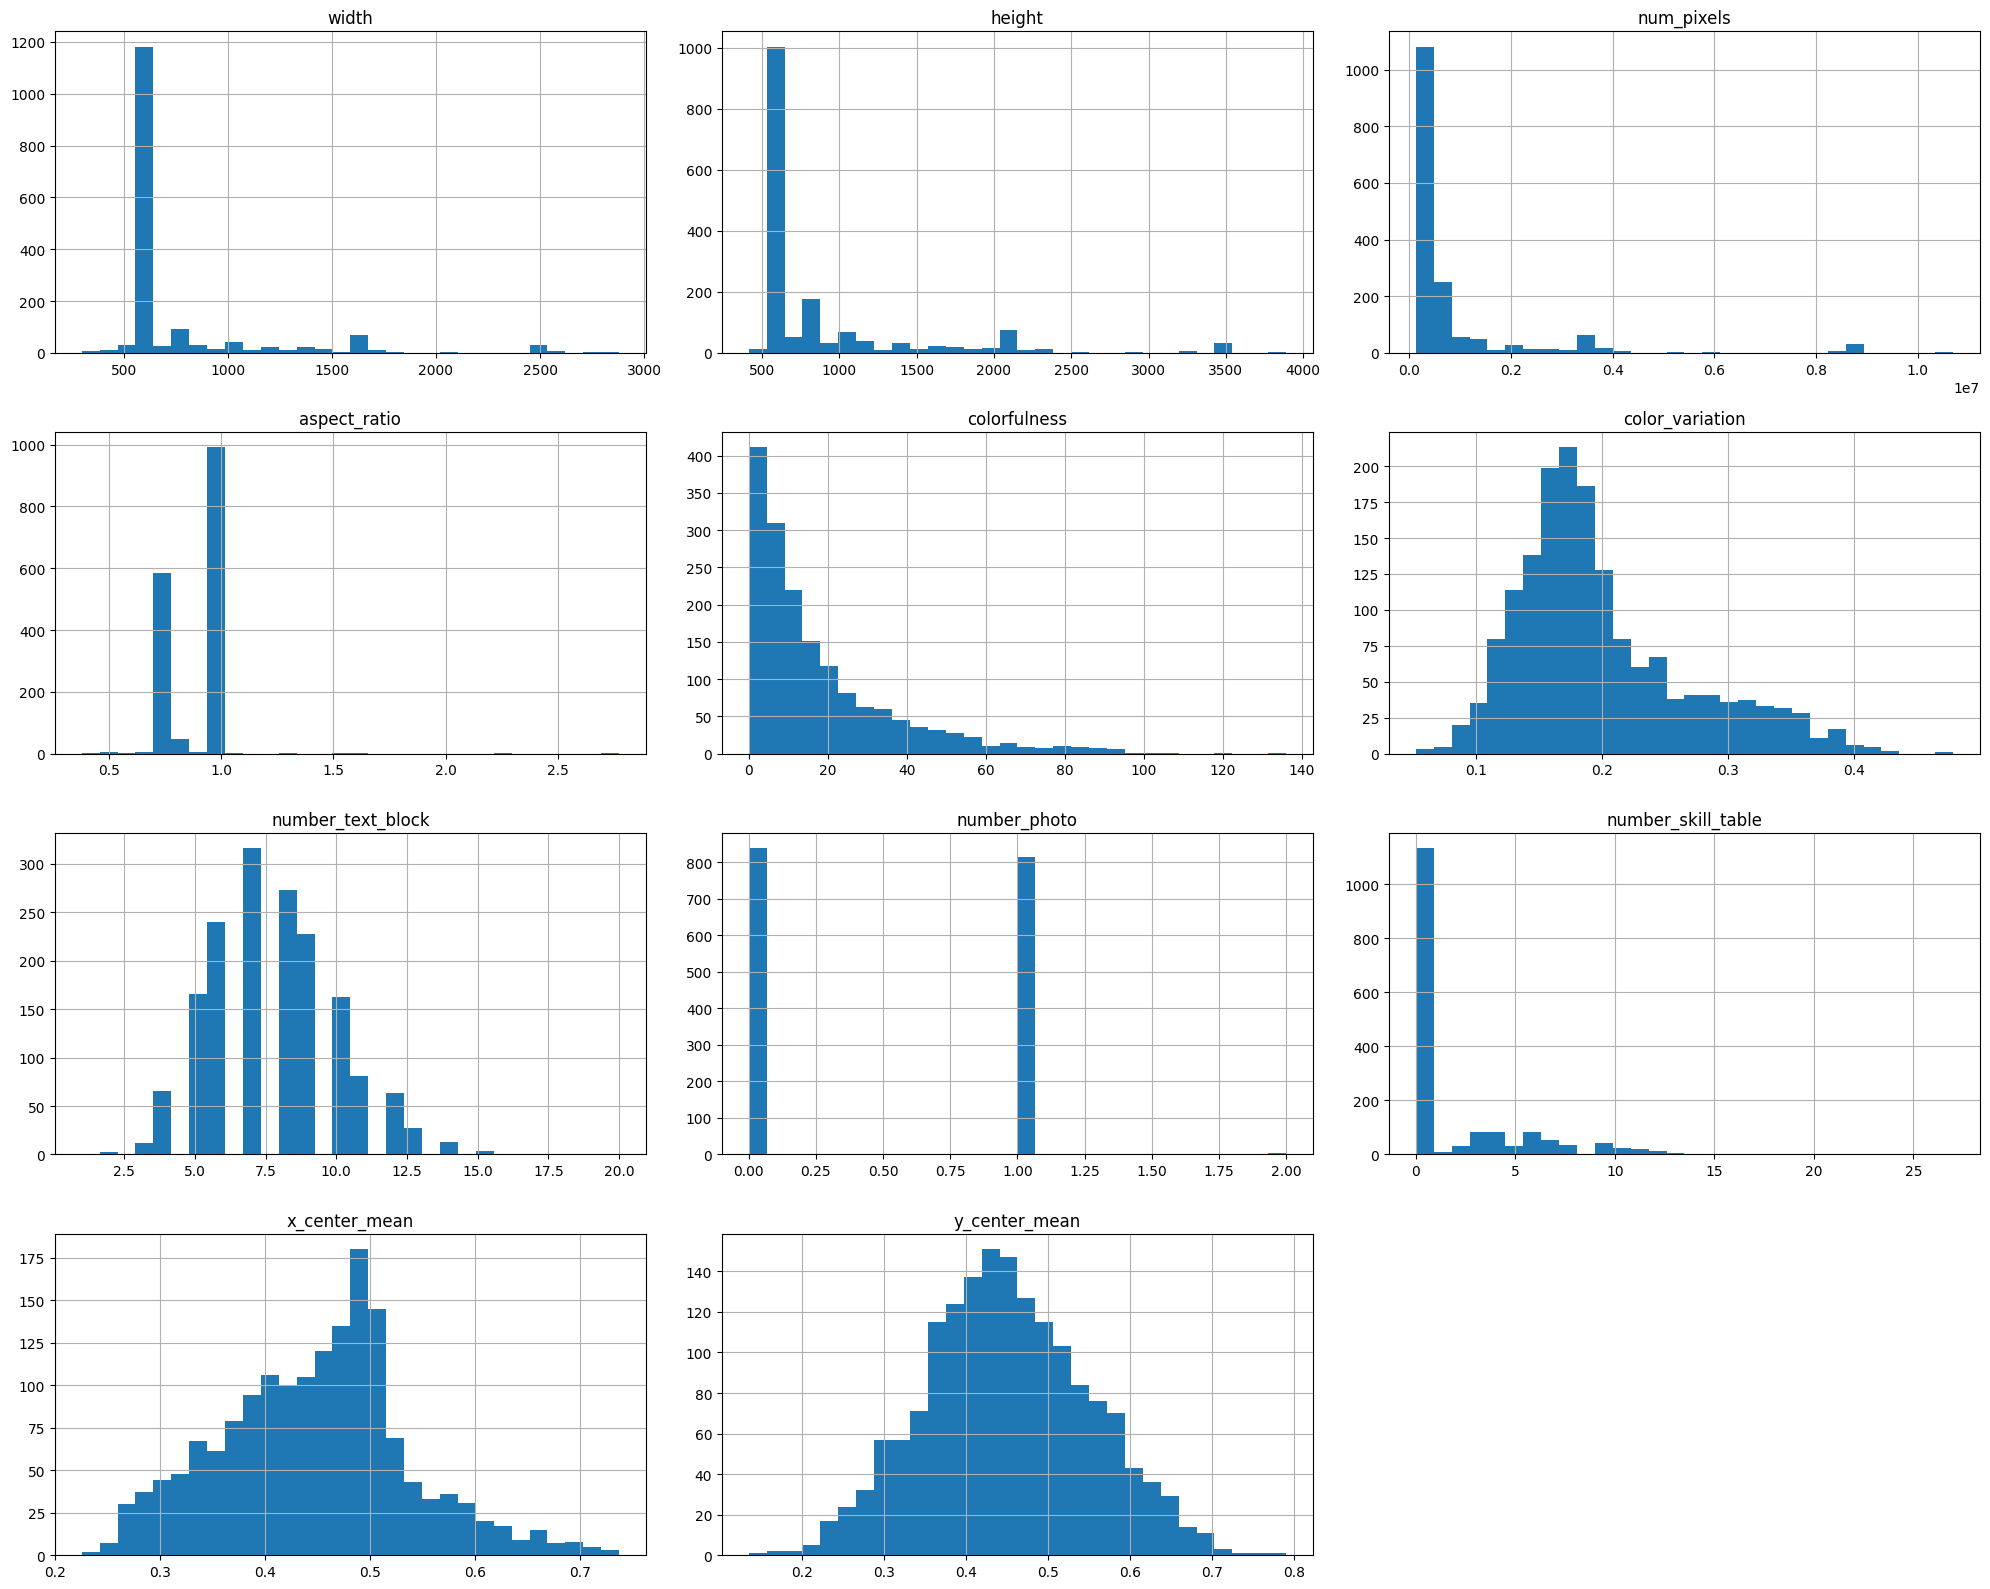

In [32]:
df_skill_table[numeric_cols_yolo].hist(figsize=(20,16), bins=30)
plt.tight_layout()
plt.show()

#### 1.2.2 YOLO benchmark chart

In [48]:
def plot_yolo_vs_batch(df, y_col, x_col="batch_config", title=None, df_name=None):
    """
    Plota benchmark YOLO:
    X -> coluna escolhida (x_col)
    Y -> coluna escolhida (y_col)
    Linha -> yolo_version
    """

    # ordenar pelos valores de X
    df_plot = df.sort_values(x_col)

    plt.figure(figsize=(11, 6))

    # linhas por versão YOLO
    for version, group in df_plot.groupby("yolo_version"):
        plt.plot(
            group[x_col],
            group[y_col],
            marker="o",
            markersize=7,
            linewidth=2.5,
            label=version
        )

    # --- ticks discretos se X for inteiro ---
    if pd.api.types.is_numeric_dtype(df_plot[x_col]):
        xmin = df_plot[x_col].min()
        xmax = df_plot[x_col].max()

        # só faz ticks 1-a-1 se parecer inteiro
        if float(xmin).is_integer() and float(xmax).is_integer():
            plt.xticks(np.arange(int(xmin), int(xmax) + 1, 1))

    # --- limites Y bonitos ---
    ymin = df_plot[y_col].min()
    ymax = df_plot[y_col].max()
    margin = (ymax - ymin) * 0.05 if ymax != ymin else 0.01
    plt.ylim(ymin - margin, ymax + margin)

    # labels
    plt.xlabel(x_col, fontsize=12)
    plt.ylabel(y_col, fontsize=12)

    # título automático
    if title is None:
        base = f"YOLO Benchmark: {y_col} vs {x_col}"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(title="YOLO version")

    plt.tight_layout()
    plt.show()


mAP50-95 vs batch

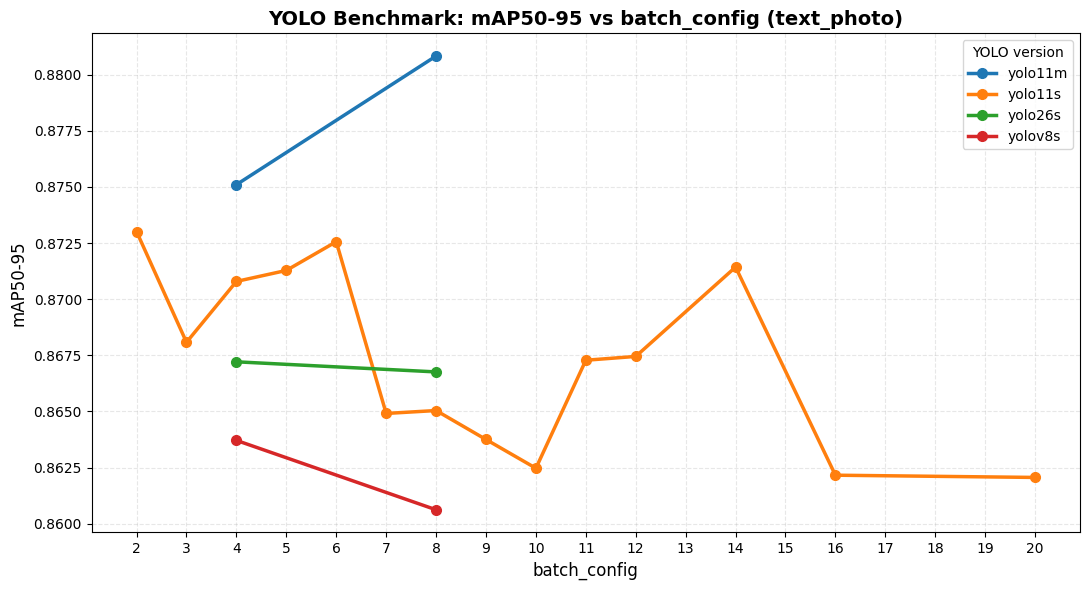

In [50]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50-95", df_name= "text_photo")

mAP50 vs batch

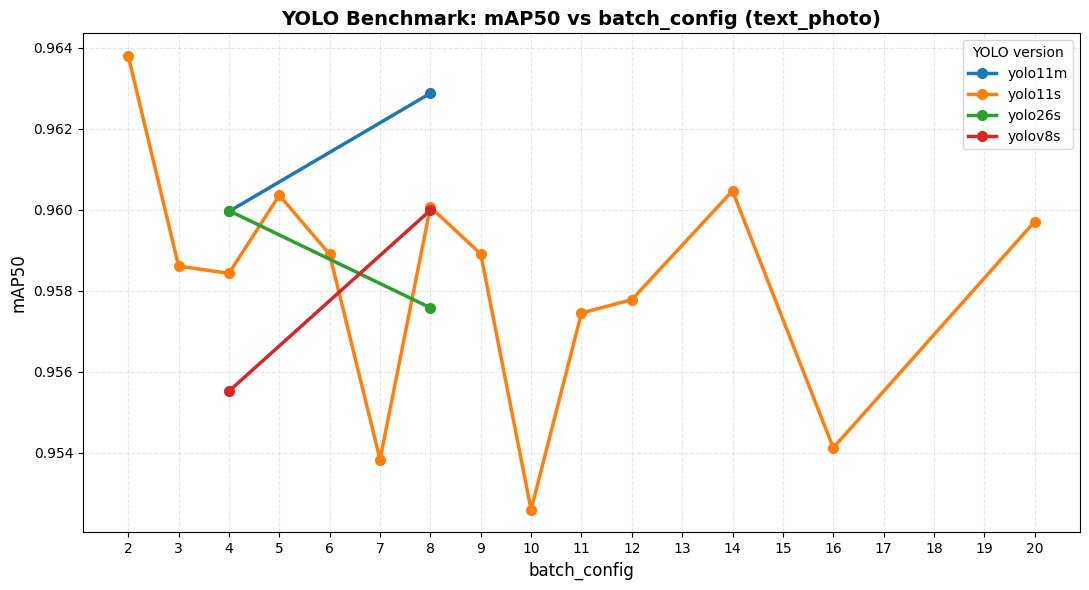

In [51]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50", df_name= "text_photo")

Precision vs batch

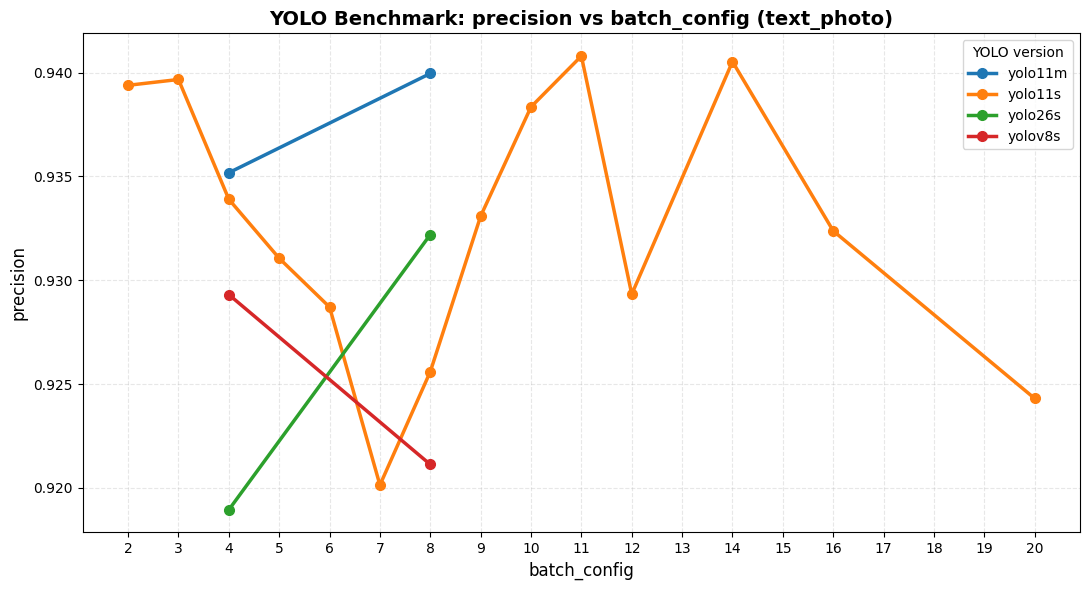

In [52]:
plot_yolo_vs_batch(df_yolo_text_photo, "precision", df_name= "text_photo")

Recall vs batch

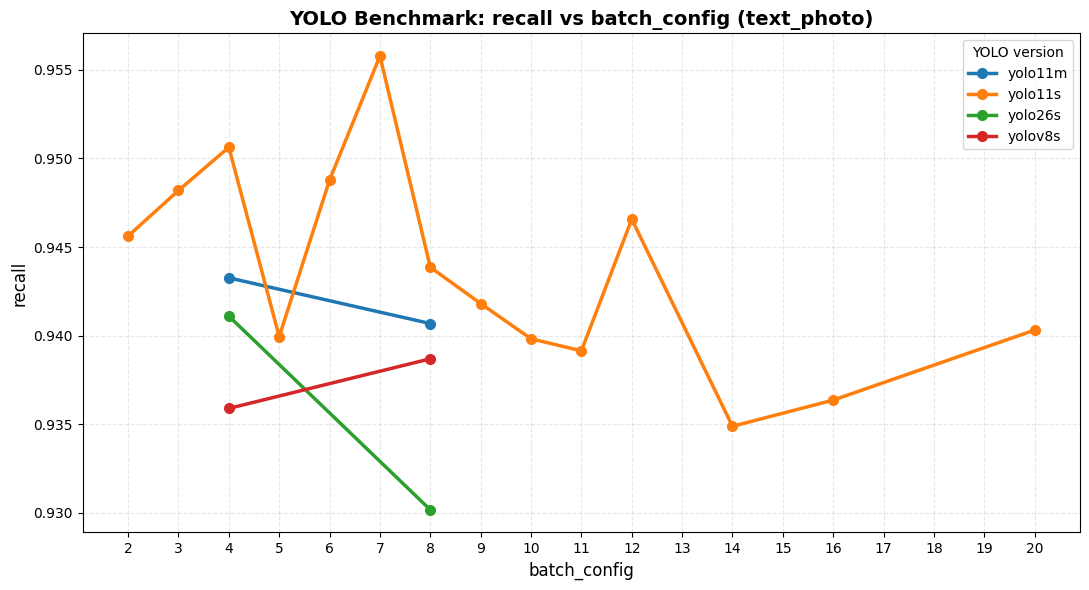

In [53]:
plot_yolo_vs_batch(df_yolo_text_photo, "recall", df_name= "text_photo")

Val_box_loss vs batch

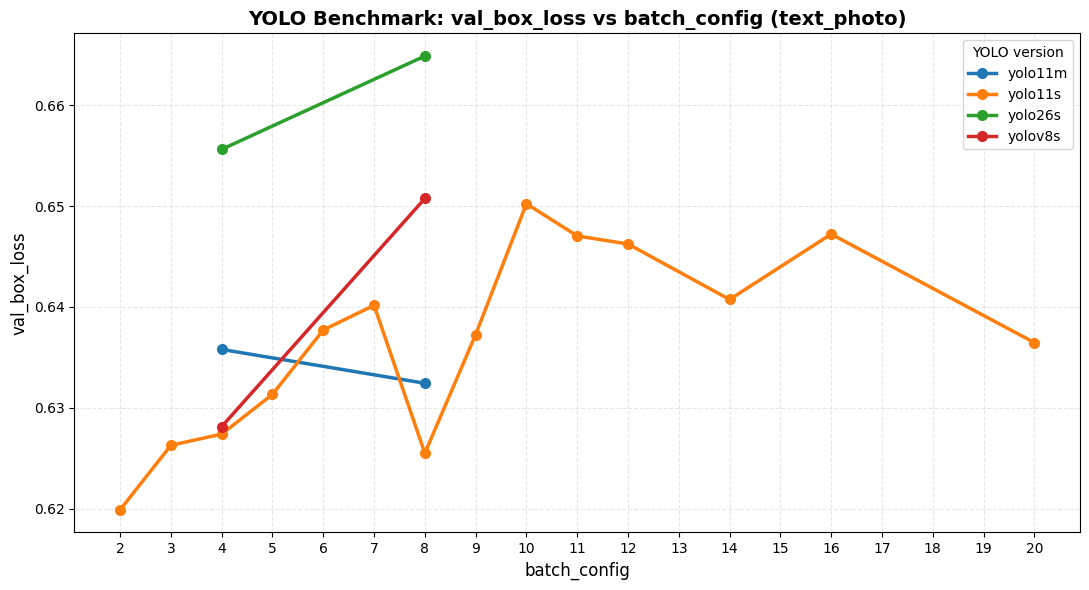

In [54]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_box_loss", df_name= "text_photo")

Val_cls_loss vs batch

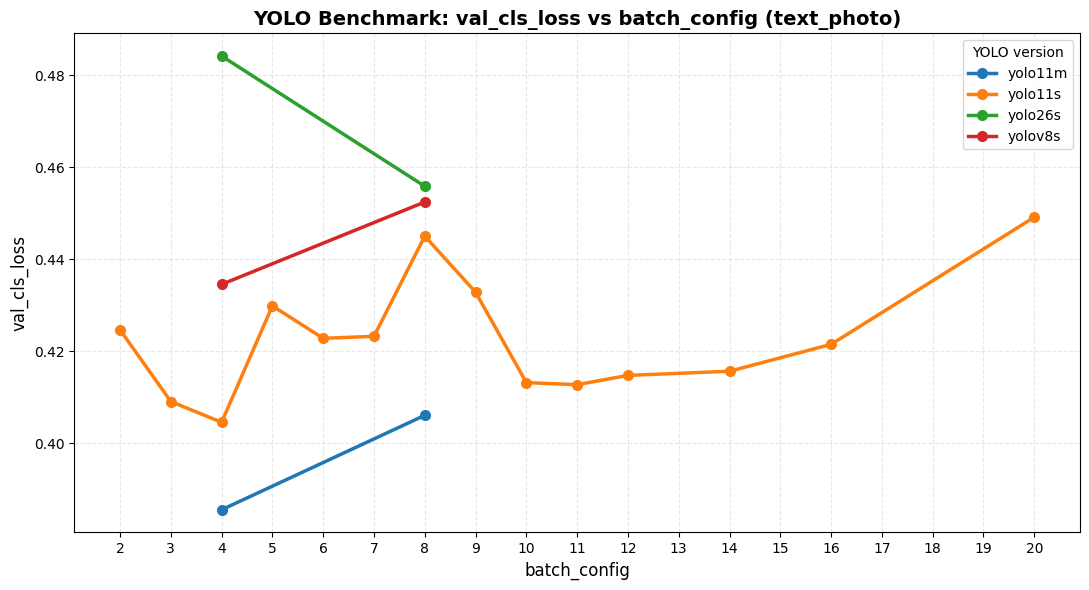

In [55]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_cls_loss", df_name= "text_photo")

Val_dfl_loss vs batch

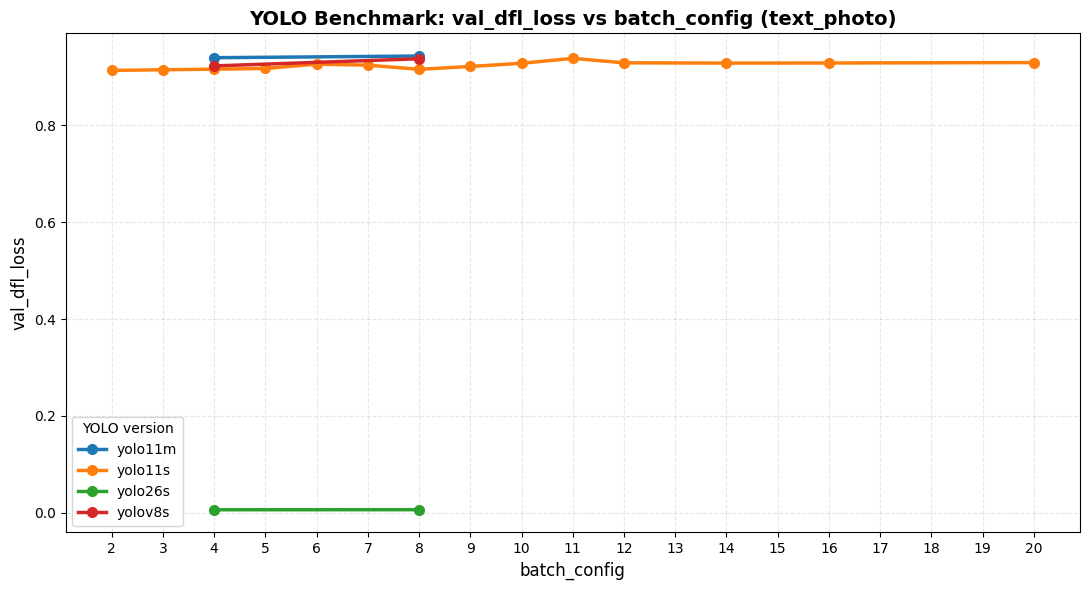

In [56]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_dfl_loss", df_name= "text_photo")

FPS vs batch

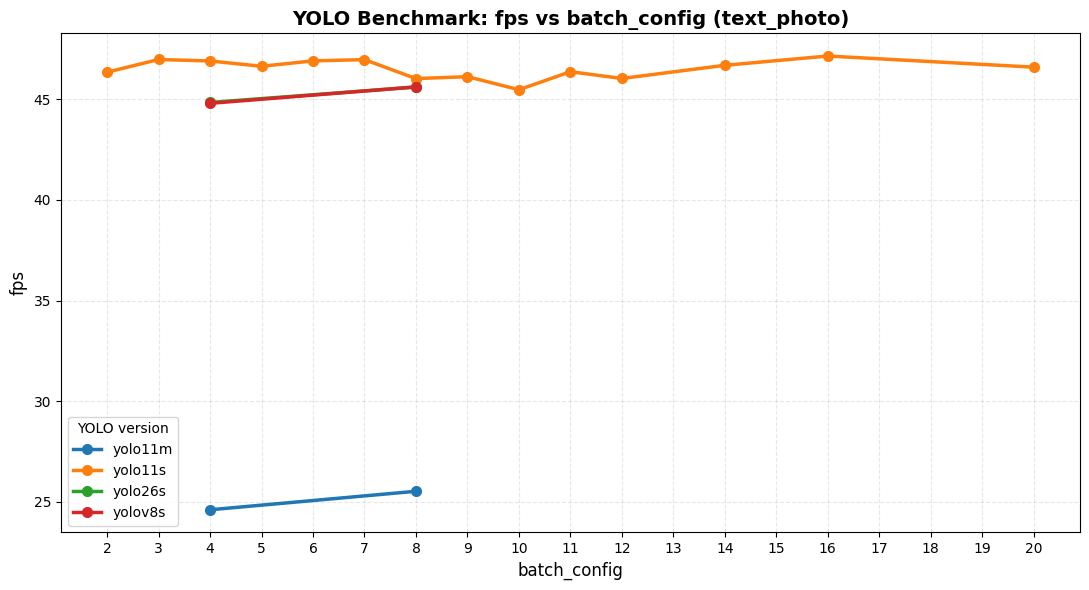

In [57]:
plot_yolo_vs_batch(df_yolo_text_photo, "fps", df_name= "text_photo")

Ms_per_image vs batch

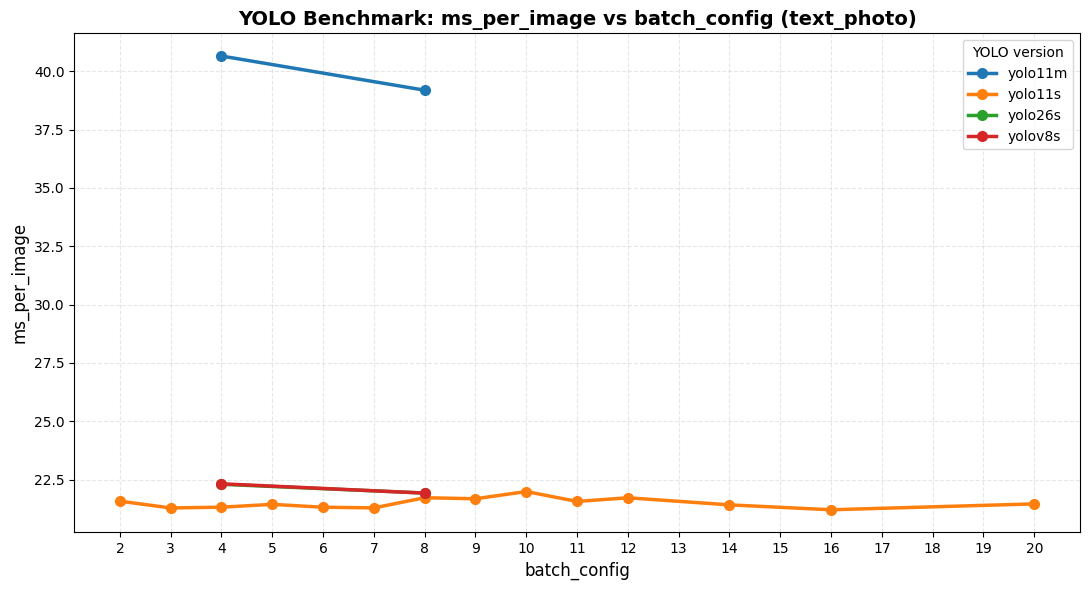

In [58]:
plot_yolo_vs_batch(df_yolo_text_photo, "ms_per_image", df_name= "text_photo")

mAP50-95 vs ms_per_image

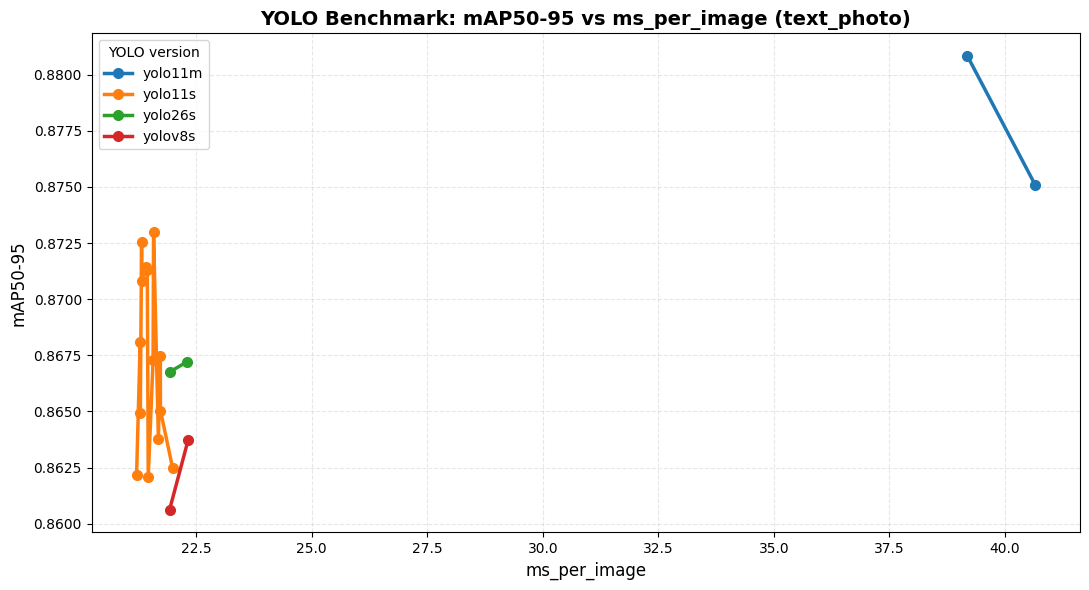

In [59]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50-95", "ms_per_image", df_name= "text_photo")

mAP50 vs ms_per_image

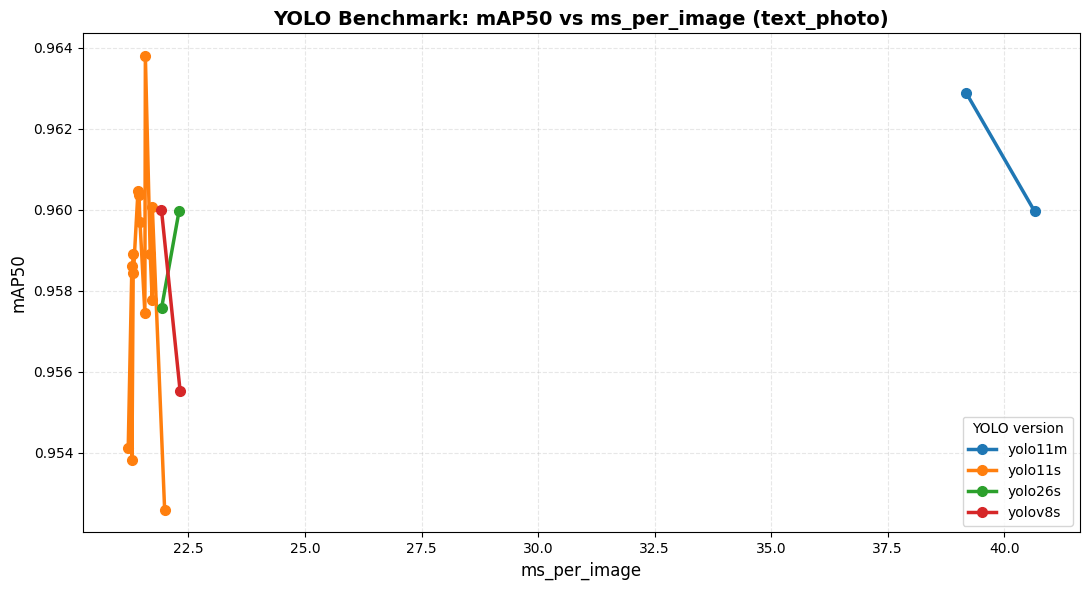

In [60]:
plot_yolo_vs_batch(df_yolo_text_photo, "mAP50","ms_per_image", df_name= "text_photo")

Precision vs ms_per_image

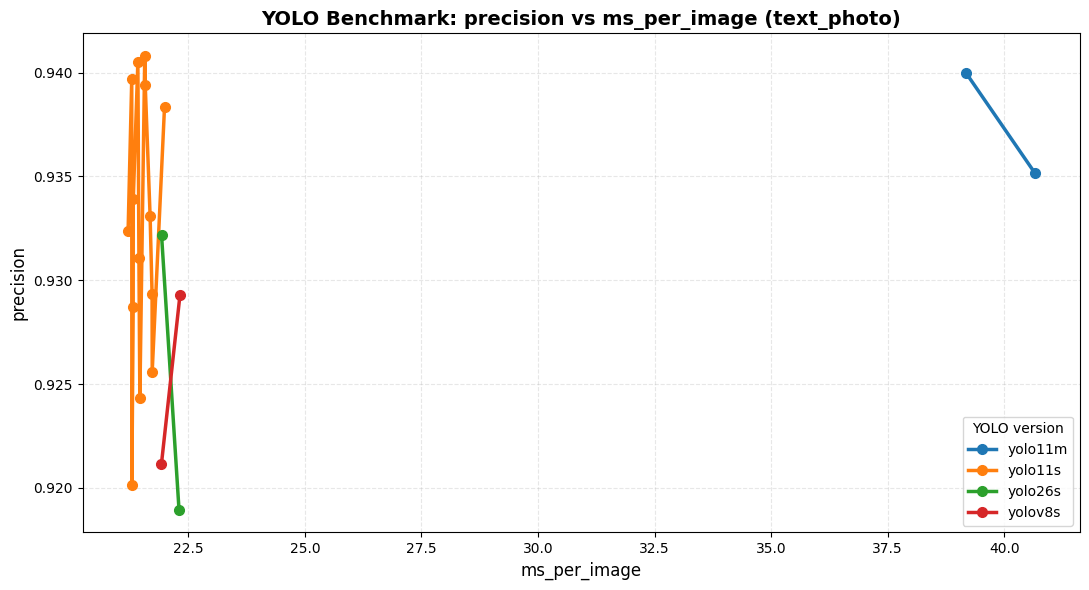

In [61]:
plot_yolo_vs_batch(df_yolo_text_photo, "precision", "ms_per_image",df_name= "text_photo")

Recall vs ms_per_image

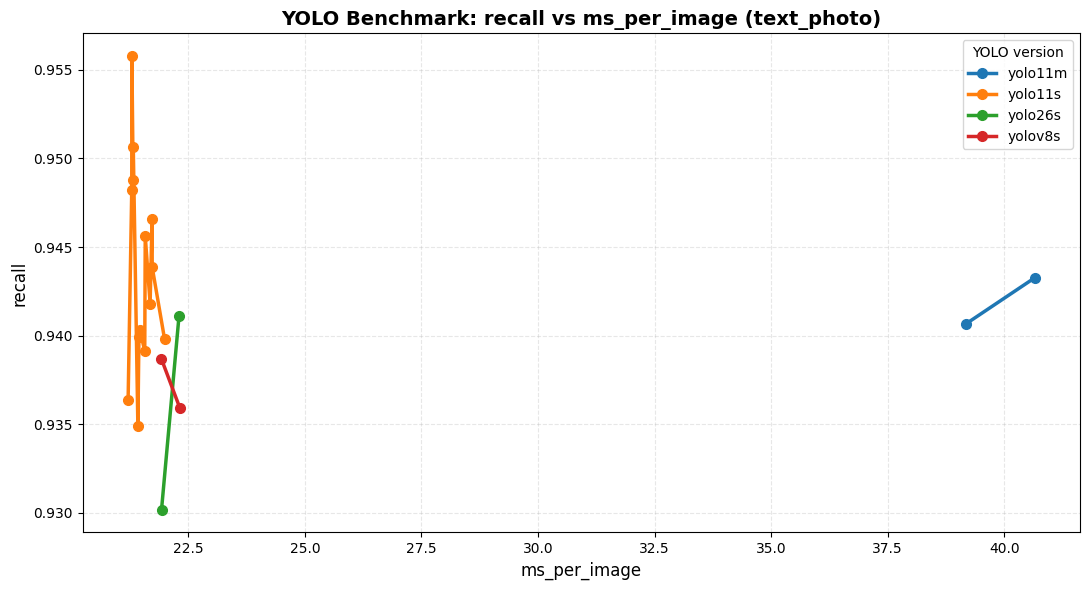

In [62]:
plot_yolo_vs_batch(df_yolo_text_photo, "recall", "ms_per_image",df_name= "text_photo")

Val_box_loss vs ms_per_image

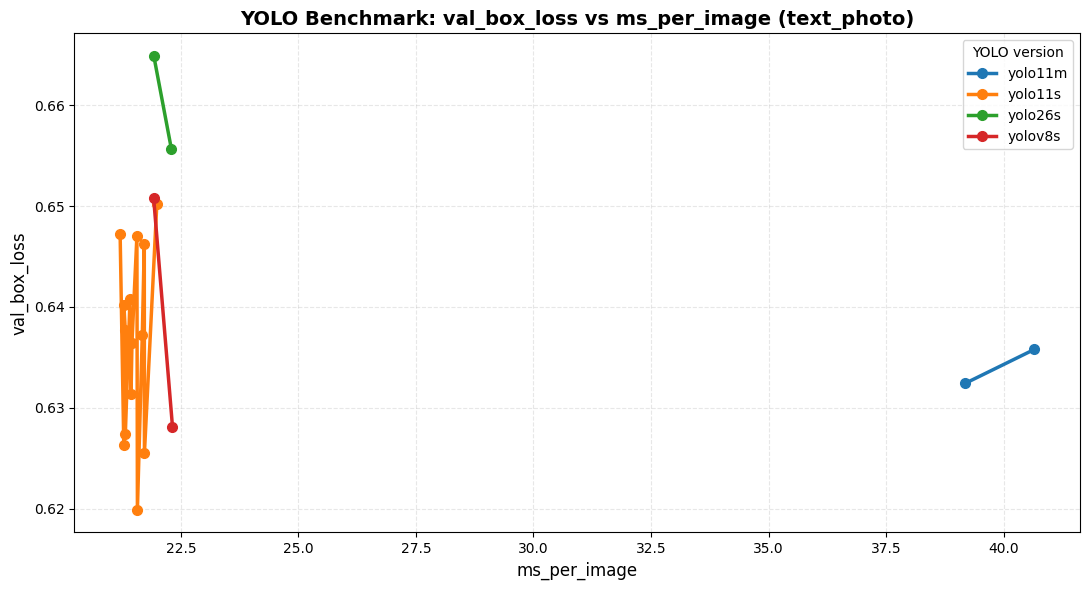

In [63]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_box_loss","ms_per_image",df_name= "text_photo")

Val_cls_loss vs ms_per_image

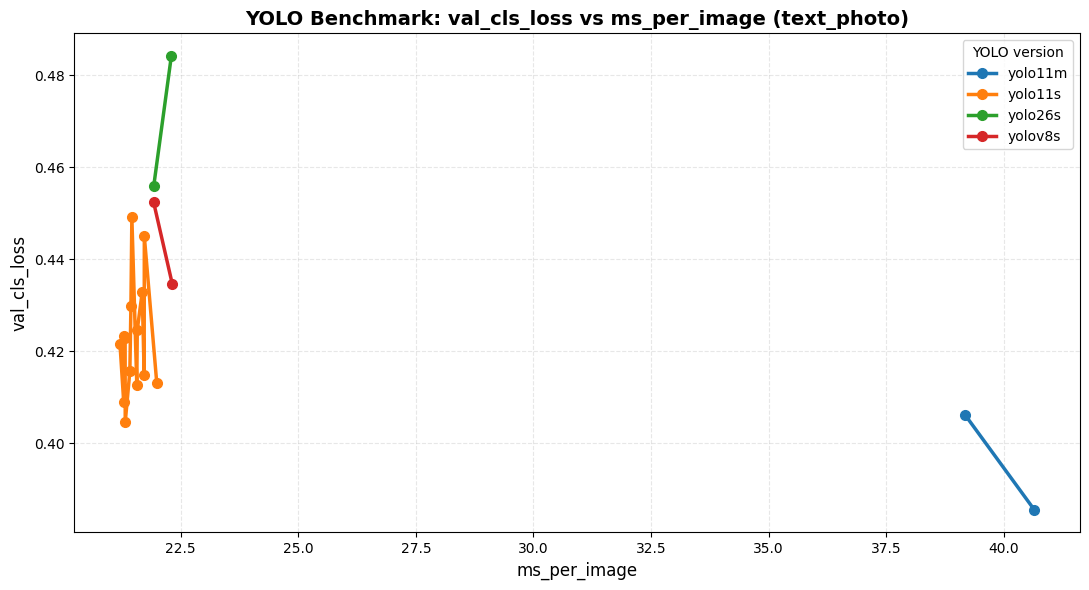

In [64]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_cls_loss", "ms_per_image",df_name= "text_photo")

Val_dfl_loss vs ms_per_image

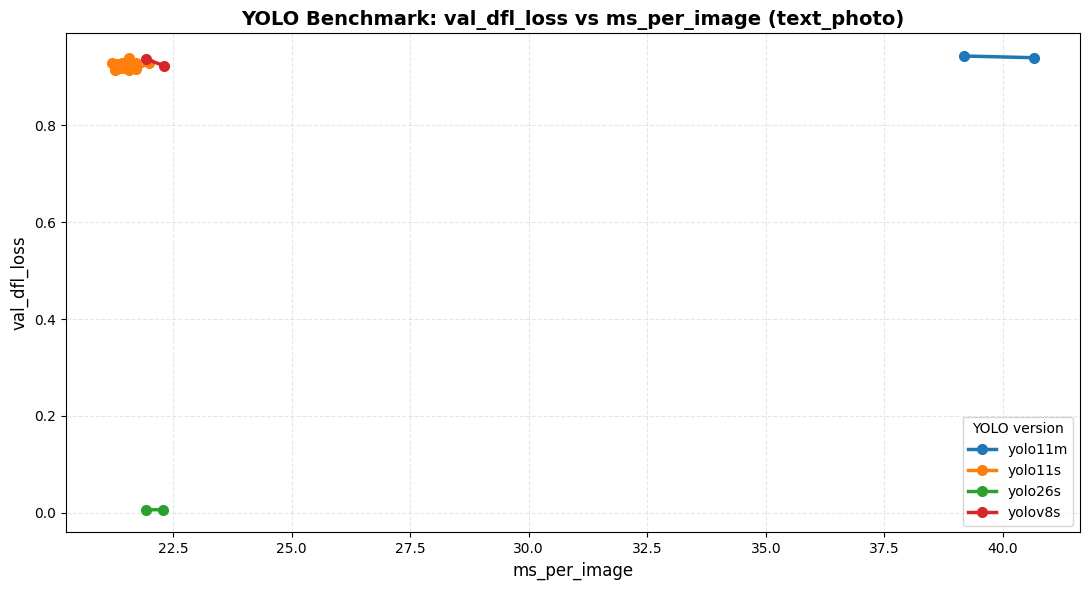

In [65]:
plot_yolo_vs_batch(df_yolo_text_photo, "val_dfl_loss", "ms_per_image",df_name= "text_photo")

#### 1.2.2 YOLO benchmark ordered bar chart

In [66]:
def plot_sorted_bar(
    df,
    y_col,
    group_col="yolo_version",
    title=None,
    df_name=None,
    ascending=True,
    agg_func="max",
    figsize=(10, 6)
):
    """
    Gráfico de barras ordenado com:
    - 1 valor por modelo (agregação)
    - cores diferentes por barra

    Parâmetros:
    - agg_func: "max", "mean", "min", etc.
    """

    # --- garantir 1 valor por modelo ---
    df_grouped = (
        df.groupby(group_col)[y_col]
        .agg(agg_func)
        .reset_index()
    )

    # --- ordenar ---
    df_plot = df_grouped.sort_values(y_col, ascending=ascending)

    plt.figure(figsize=figsize)

    # --- cores diferentes ---
    colors = plt.cm.tab20(np.linspace(0, 1, len(df_plot)))

    plt.bar(df_plot[group_col].astype(str), df_plot[y_col], color=colors)

    # labels
    plt.xlabel(group_col, fontsize=12)
    plt.ylabel(y_col, fontsize=12)

    # título automático
    if title is None:
        base = f"{y_col} ({agg_func}) ordered by {group_col}"
        title = f"{base} ({df_name})" if df_name else base

    plt.title(title, fontsize=14, weight="bold")

    # rodar labels
    plt.xticks(rotation=45, ha="right")

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()



mAP50-95

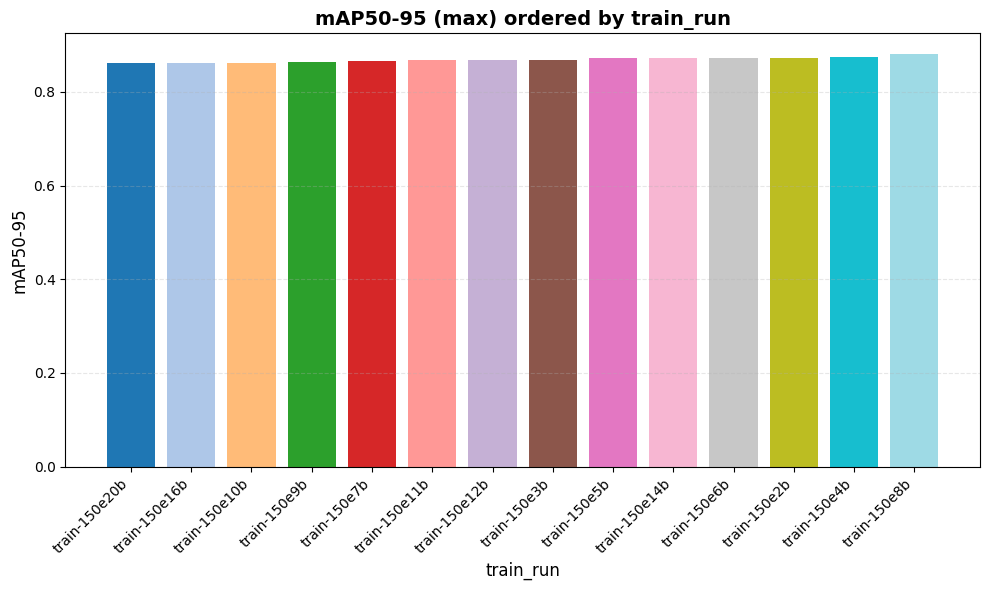

In [67]:
plot_sorted_bar(df_yolo, "mAP50-95", group_col="train_run")


mAP50

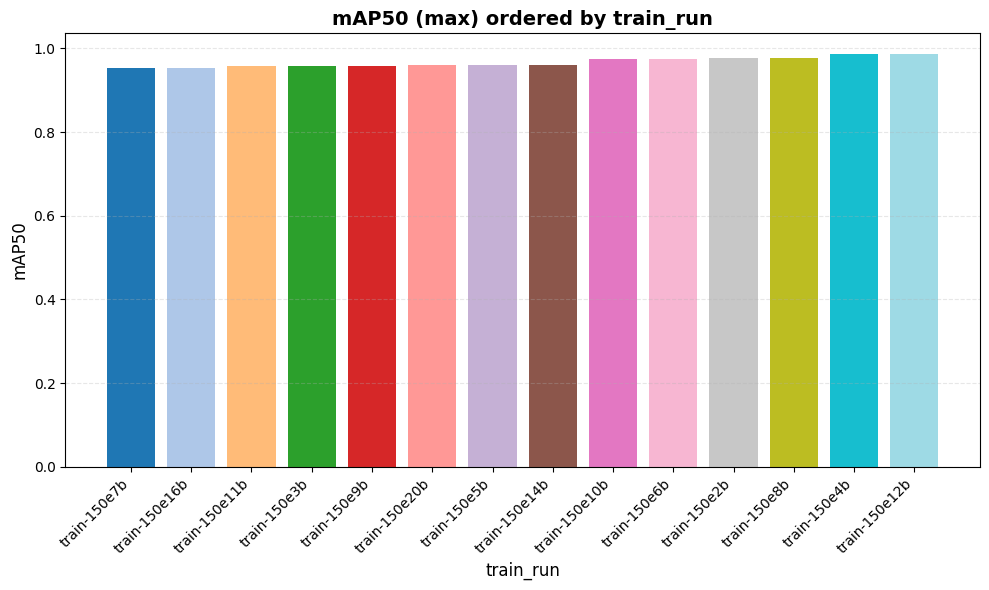

In [68]:
plot_sorted_bar(df_yolo, "mAP50", group_col="train_run")

Precision

In [69]:
plot_sorted_bar(df_yolo, "Precision", group_col="train_run")

KeyError: 'Column not found: Precision'

Recall

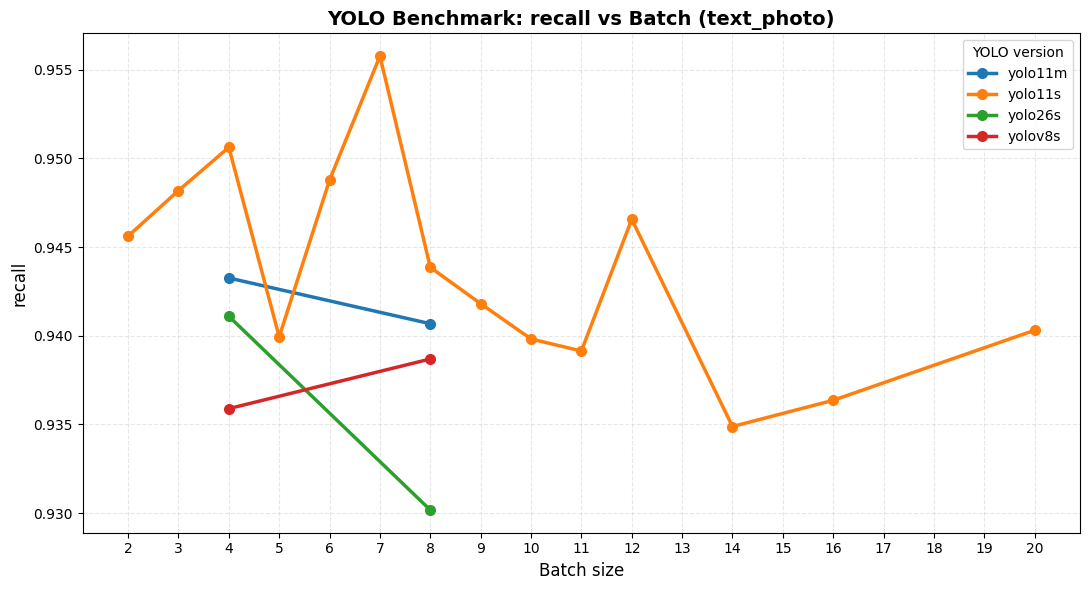

In [ ]:
plot_sorted_bar(df_yolo, "Recall", group_col="train_run")

Val_box_loss

In [70]:
plot_sorted_bar(df_yolo, "Val_box_loss", group_col="train_run")

KeyError: 'Column not found: Val_box_loss'

Val_cls_loss

In [71]:
plot_sorted_bar(df_yolo, "Val_cls_loss", group_col="train_run")

KeyError: 'Column not found: Val_cls_loss'

Val_dfl_loss

In [72]:
plot_sorted_bar(df_yolo, "Val_dfl_loss", group_col="train_run")

KeyError: 'Column not found: Val_dfl_loss'

FPS

In [73]:
plot_sorted_bar(df_yolo, "FPS", group_col="train_run")

KeyError: 'Column not found: FPS'

Ms_per_image

In [74]:
plot_sorted_bar(df_yolo, "Ms_per_image", group_col="train_run")

KeyError: 'Column not found: Ms_per_image'